In [2]:
import glob
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    return tertiles

In [3]:
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv")
plotdir = "/home/kperny/VolMIP_stratosphere/plots/flag_changes/"

In [1]:
# sns.boxplot(x="model", y="nao",
#             hue="nao_flag", palette=["b", "grey", "r"],
#             data=df_flags)
# plt.title('NAO flags/indices for piControl')
# plt.savefig(plotdir + 'background/nao_flags-indices.png', dpi=200)
# plt.show()
# sns.boxplot(x="model", y="enso",
#             hue="enso_flag", palette=["b", "grey", "r"],
#             data=df_flags)
# plt.title('ENSO flags/indices for piControl')
# plt.savefig(plotdir + 'background/enso_flags-indices.png', dpi=200)

In [ ]:
datadir = "/sto4/data/Intermediate/VolMIP/"
models = ['CanESM5', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'UKESM1-0-LL']
collect_df = []
for model in models:
    df_model = df_flags.where(df_flags['model'] == model).dropna()
    data_control = xr.open_dataset(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_NAO_djf*.nc')[0], decode_times=time_coder)
    tertiles = calculate_tercile_flags((data_control- data_control.mean('time') ) /  np.sqrt(data_control.var('time')), 'zg')
    nao = []
    for ens in df_model['realization']:
        data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
        nao.append((calculate_djf_mean(data_volc).sel(time='1992') - data_control.mean('time') ) /  np.sqrt(data_control.var('time')))
        
    nao_volc = xr.concat(nao, dim='realization')
    nao_volc['realization'] = df_model['realization'].values
    df_volc = nao_volc.rename({'zg': 'nao'}).nao.to_dataframe().reset_index().drop(['time', 'plev', 'lat', 'lon'], axis=1)

    df_volc['nao_flag'] = pd.cut(df_volc['nao'], bins=tertiles, labels=[-1,0,1])
    df_volc['experiment'] = 'volc'
    df_cut = df_model[['realization', 'nao', 'nao_flag']]
    df_cut['experiment'] = 'piControl'

    df = pd.concat([df_cut, df_volc])
    df['model'] = model
    collect_df.append(df)

    sns.boxplot(x="nao_flag", y="nao",
                hue="experiment", palette=['C0', 'C1'],
                data=df)
    plt.title('NAO flags/indices for ' + model)
    plt.savefig(plotdir + model + '_nao-change.png', dpi=200)
    plt.close()

r1i1p2f1
r2i1p2f1
r3i1p2f1
r4i1p2f1
r5i1p2f1
r6i1p2f1
r7i1p2f1
r8i1p2f1
r9i1p2f1
r10i1p2f1
r11i1p2f1
r12i1p2f1
r13i1p2f1
r14i1p2f1
r15i1p2f1
r16i1p2f1
r17i1p2f1
r18i1p2f1
r19i1p2f1
r20i1p2f1
r21i1p2f1
r22i1p2f1
r23i1p2f1
r24i1p2f1
r25i1p2f1
r26i1p2f1
r27i1p2f1
r28i1p2f1
r29i1p2f1
r30i1p2f1
r31i1p2f1
r32i1p2f1
r33i1p2f1
r34i1p2f1
r35i1p2f1
r36i1p2f1
r37i1p2f1
r38i1p2f1
r39i1p2f1
r40i1p2f1


/tmp/ipykernel_850037/2773743821.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


r1i1p1f2
r2i1p1f2
r3i1p1f2
r4i1p1f2
r5i1p1f2
r6i1p1f2
r7i1p1f2
r8i1p1f2
r9i1p1f2
r10i1p1f2
r11i1p1f2
r12i1p1f2
r13i1p1f2
r14i1p1f2
r15i1p1f2
r16i1p1f2
r17i1p1f2
r18i1p1f2
r19i1p1f2
r20i1p1f2
r21i1p1f2
r22i1p1f2
r23i1p1f2
r24i1p1f2
r25i1p1f2


/tmp/ipykernel_850037/2773743821.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


r1i1p1f1
r2i1p1f1
r3i1p1f1
r4i1p1f1
r5i1p1f1
r6i1p1f1
r7i1p1f1
r8i1p1f1
r9i1p1f1
r10i1p1f1
r11i1p1f1
r12i1p1f1
r13i1p1f1
r14i1p1f1
r15i1p1f1
r16i1p1f1
r17i1p1f1
r18i1p1f1
r19i1p1f1
r20i1p1f1
r21i1p1f1
r22i1p1f1
r23i1p1f1
r24i1p1f1
r25i1p1f1


...

/tmp/ipykernel_850037/2773743821.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_850037/2773743821.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_850037/2773743821.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime object

r9i7p1f2
r9i8p1f2
r9i9p1f2


/tmp/ipykernel_850037/2773743821.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


r1i1p1f2
r2i1p1f2
r3i1p1f2
r4i1p1f2
r5i1p1f2
r6i1p1f2
r7i1p1f2
r8i1p1f2
r9i1p1f2
r10i1p1f2
r11i1p1f2
r12i1p1f2
r13i1p1f2
r14i1p1f2
r15i1p1f2
r16i1p1f2
r17i1p1f2
r18i1p1f2
r19i1p1f2
r20i1p1f2
r21i1p1f2
r22i1p1f2
r23i1p1f2
r24i1p1f2
r25i1p1f2


/tmp/ipykernel_850037/2773743821.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


In [5]:
df_nao = pd.concat(collect_df)
df_nao = df_nao.set_index(['model', 'realization', 'experiment']).sort_index()
df_nao.reset_index().to_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv", index=False)
df_nao = df_nao.reset_index().set_index(['model', 'realization']).sort_index()

In [6]:
# calculate amount of pi Control
pi_Control = df_nao.where(df_nao['experiment']=='piControl').dropna().drop(['experiment', 'nao'], axis=1).reset_index()
pi_Control['count'] = 1
pi_Control.groupby(['model', 'nao_flag']).sum()

realization  \
model         nao_flag                                                      
CanESM5       -1.0      r12i1p2f1r13i1p2f1r16i1p2f1r19i1p2f1r22i1p2f1r...   
               0.0      r10i1p2f1r18i1p2f1r1i1p2f1r21i1p2f1r29i1p2f1r2...   
               1.0      r11i1p2f1r14i1p2f1r15i1p2f1r17i1p2f1r20i1p2f1r...   
GISS-E2-1-G   -1.0      r18i1p1f2r1i10p1f2r1i4p1f2r1i7p1f2r20i1p1f2r21...   
               0.0      r10i1p1f2r12i1p1f2r13i1p1f2r14i1p1f2r1i1p1f2r1...   
               1.0      r11i1p1f2r15i1p1f2r16i1p1f2r17i1p1f2r19i1p1f2r...   
MIROC-ES2L    -1.0      r14i1p1f2r22i1p1f2r23i1p1f2r2i1p1f2r6i1p1f2r7i...   
               0.0      r10i1p1f2r11i1p1f2r16i1p1f2r17i1p1f2r18i1p1f2r...   
               1.0      r12i1p1f2r13i1p1f2r15i1p1f2r19i1p1f2r1i1p1f2r2...   
MPI-ESM1-2-LR -1.0      r11i1p1f1r12i1p1f1r16i1p1f1r18i1p1f1r1i1p1f1r2...   
               0.0      r13i1p1f1r14i1p1f1r15i1p1f1r17i1p1f1r19i1p1f1r...   
               1.0      r10i1p1f1r20i1p1f1r25i1p1f1r2i1p1f1r4i1p1f1r7i...   
UKESM1-0-LL   -1.0      r11i1p1f2r17i1p1f2r1i1p1f2r2i1p1f2r4i1p1f2r5i1...   
               0.0      r10i1p1f2r12i1p1f2r13i1p1f2r14i1p1f2r15i1p1f2r...   
               1.0      r19i1p1f2r20i1p1f2r21i1p1f2r22i1p1f2r23i1p1f2r...   

                        count  
model         nao_flag         
CanESM5       -1.0         13  
               0.0         15  
               1.0         12  
GISS-E2-1-G   -1.0         35  
               0.0         46  
               1.0         40  
MIROC-ES2L    -1.0          6  
               0.0          8  
               1.0         11  
MPI-ESM1-2-LR -1.0         10  
               0.0          7  
               1.0          8  
UKESM1-0-LL   -1.0          9  
               0.0          9  
               1.0          7

In [7]:
# how many nao- in piControl changed to what or stayed the same
index = df_nao.where((df_nao['experiment']=='piControl') & (df_nao['nao_flag'] == -1)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df_nao.where((df_nao['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          6
 0.0          1
 1.0          6
GISS-E2-1-G
          count
nao_flag       
-1.0         11
 0.0          7
 1.0         17
MIROC-ES2L
          count
nao_flag       
-1.0          3
 0.0          3
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          3
 0.0          4
 1.0          3
UKESM1-0-LL
          count
nao_flag       
-1.0          2
 0.0          3
 1.0          4


In [29]:
# how many nao0 in piControl changed to what or stayed the same
index = df_nao.where((df_nao['experiment']=='piControl') & (df_nao['nao_flag'] == 0)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df_nao.where((df_nao['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          7
 0.0          4
 1.0          4
GISS-E2-1-G
          count
nao_flag       
-1.0          2
 0.0          9
 1.0          8
MIROC-ES2L
          count
nao_flag       
-1.0          1
 0.0          3
 1.0          4
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          3
 0.0          1
 1.0          3
UKESM1-0-LL
          count
nao_flag       
-1.0          2
 0.0          3
 1.0          4


In [8]:
# how many nao+ in piControl changed to what or stayed the same
index = df_nao.where((df_nao['experiment']=='piControl') & (df_nao['nao_flag'] == 1)).dropna().drop(['experiment', 'nao', 'nao_flag'], axis=1)
df_volc = df_nao.where((df_nao['experiment']=='volc')).dropna().drop(['experiment', 'nao'], axis=1)
df_volc['count'] = 1
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('nao_flag').sum())

CanESM5
          count
nao_flag       
-1.0          6
 0.0          2
 1.0          4
GISS-E2-1-G
          count
nao_flag       
-1.0          5
 0.0         21
 1.0         14
MIROC-ES2L
          count
nao_flag       
-1.0          4
 0.0          3
 1.0          4
MPI-ESM1-2-LR
          count
nao_flag       
-1.0          2
 0.0          2
 1.0          4
UKESM1-0-LL
          count
nao_flag       
-1.0          2
 0.0          2
 1.0          3


/tmp/ipykernel_850037/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


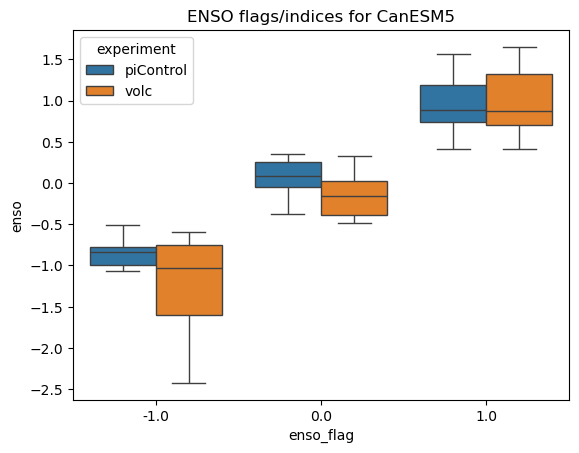

/tmp/ipykernel_850037/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


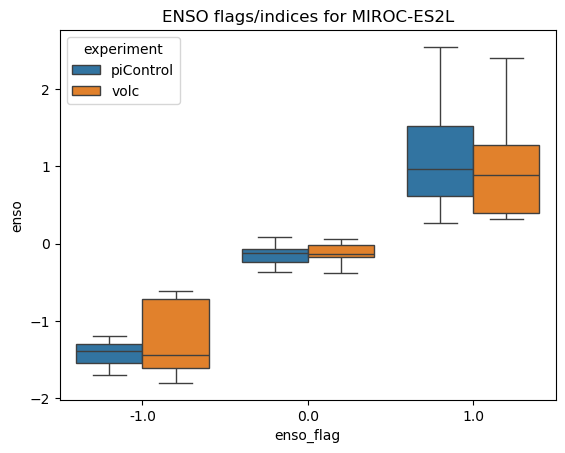

/tmp/ipykernel_850037/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


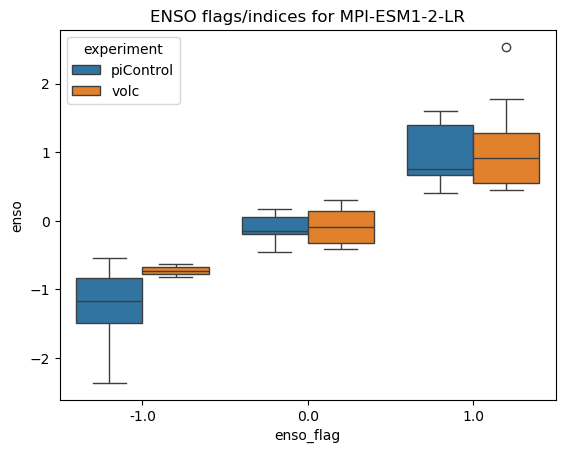

/tmp/ipykernel_850037/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_850037/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_850037/2794516501.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime obje

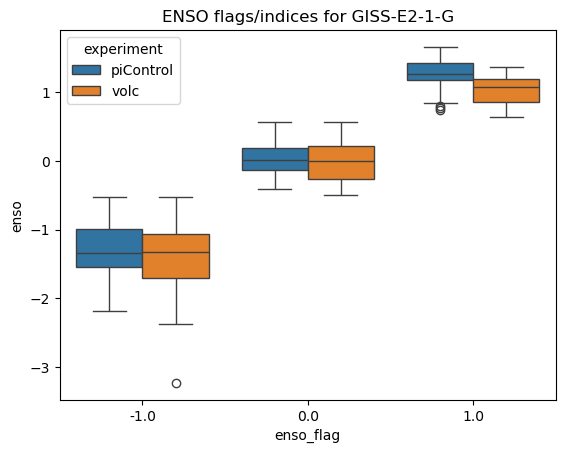

/tmp/ipykernel_850037/2794516501.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


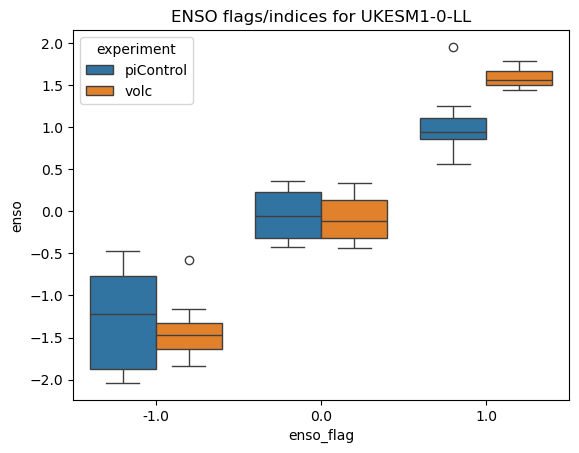

In [9]:
datadir = "/sto4/data/Intermediate/VolMIP/"
models = ['CanESM5', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'GISS-E2-1-G', 'UKESM1-0-LL']

collect_df = []
for model in models:
    df_model = df_flags.where(df_flags['model'] == model).dropna()

    data_control = xr.open_dataset(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_Nino34_djf*.nc')[0], decode_times=time_coder)
    tertiles = calculate_tercile_flags((data_control- data_control.mean('time') ) /  np.sqrt(data_control.var('time')), 'tos')
    enso = []
    for ens in df_model['realization']:
        data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/ENSO_*' + ens + '*_fixed_dates.nc')[0])
        enso.append((calculate_djf_mean(data_volc).sel(time='1992') - data_control.mean('time') ) /  np.sqrt(data_control.var('time')))
        
    enso_volc = xr.concat(enso, dim='realization')
    enso_volc['realization'] = df_model['realization'].values
    df_volc = enso_volc.rename({'tos': 'enso'}).enso.to_dataframe().reset_index().drop(['time','lat', 'lon'], axis=1)

    df_volc['enso_flag'] = pd.cut(df_volc['enso'], bins=tertiles, labels=[-1,0,1])
    df_volc['experiment'] = 'volc'
    df_cut = df_model[['realization', 'enso', 'enso_flag']]
    df_cut['experiment'] = 'piControl'

    df = pd.concat([df_cut, df_volc])
    df['model'] = model
    collect_df.append(df)

    sns.boxplot(x="enso_flag", y="enso",
                hue="experiment", palette=['C0', 'C1'],
                data=df)
    plt.title('ENSO flags/indices for ' + model)
    plt.savefig(plotdir + model + '_enso-change.png', dpi=200)
    plt.show()

In [10]:
df_enso = pd.concat(collect_df)
df_enso = df_enso.set_index(['model', 'realization', 'experiment']).sort_index()
df_enso.reset_index().to_csv("/home/kperny/VolMIP_stratosphere/tab/enso_change.csv", index=False)
df_enso = df_enso.reset_index().set_index(['model', 'realization']).sort_index()

In [11]:
df = df_nao.copy()
df[['enso', 'enso_flag']] = df_enso[['enso', 'enso_flag']].values
df['category'] = np.nan

In [12]:
df['category'] = np.where((df['nao_flag'] == 0) & (df['enso_flag']==0) , 0 , df['category'])
df['category'] = np.where((df['nao_flag'] == 1) & (df['enso_flag']==0) , 1 , df['category'])
df['category'] = np.where((df['nao_flag'] == -1) & (df['enso_flag']==0) , 2 , df['category'])
df['category'] = np.where((df['nao_flag'] == 0) & (df['enso_flag']==1) , 3 , df['category'])
df['category'] = np.where((df['nao_flag'] == 0) & (df['enso_flag']==-1) , 4 , df['category'])
df['category'] = np.where((df['nao_flag'] == 1) & (df['enso_flag']==1) , 5 , df['category'])
df['category'] = np.where((df['nao_flag'] == 1) & (df['enso_flag']==-1) , 6 , df['category'])
df['category'] = np.where((df['nao_flag'] == -1) & (df['enso_flag']==1) , 7, df['category'])
df['category'] = np.where((df['nao_flag'] == -1) & (df['enso_flag']==-1) , 8 , df['category'])

In [13]:
df

experiment       nao  nao_flag      enso  enso_flag  \
model       realization                                                       
CanESM5     r10i1p2f1    piControl  0.128636       0.0  0.216737        0.0   
            r10i1p2f1         volc -1.297018      -1.0 -0.490471        0.0   
            r11i1p2f1    piControl  1.484647       1.0 -1.069283       -1.0   
            r11i1p2f1         volc -0.877253      -1.0 -1.723579       -1.0   
            r12i1p2f1    piControl -0.939510      -1.0  0.009603        0.0   
...                            ...       ...       ...       ...        ...   
UKESM1-0-LL r7i1p1f2          volc -2.041621      -1.0  1.440647        1.0   
            r8i1p1f2     piControl -1.031777      -1.0  0.943689        1.0   
            r8i1p1f2          volc  0.132394       0.0 -0.177838        0.0   
            r9i1p1f2     piControl -0.342787       0.0  0.561932        1.0   
            r9i1p1f2          volc -0.852005      -1.0 -0.427529        0.0   

                         category  
model       realization            
CanESM5     r10i1p2f1         0.0  
            r10i1p2f1         2.0  
            r11i1p2f1         6.0  
            r11i1p2f1         8.0  
            r12i1p2f1         2.0  
...                           ...  
UKESM1-0-LL r7i1p1f2          7.0  
            r8i1p1f2          7.0  
            r8i1p1f2          0.0  
            r9i1p1f2          3.0  
            r9i1p1f2          2.0  

[472 rows x 6 columns]

In [14]:
# calculate amount of pi Control
pi_Control = df.where(df['experiment']=='piControl').dropna().drop(['experiment', 'enso', 'nao_flag', 'enso_flag', 'nao'], axis=1).reset_index()
pi_Control['count'] = 1
pi_Control.groupby(['model', 'category']).sum()

realization  \
model         category                                                      
CanESM5       0.0       r10i1p2f1r18i1p2f1r21i1p2f1r2i1p2f1r38i1p2f1r4...   
              1.0                                      r15i1p2f1r25i1p2f1   
              2.0       r12i1p2f1r13i1p2f1r23i1p2f1r28i1p2f1r34i1p2f1r...   
              3.0                                               r31i1p2f1   
              4.0       r1i1p2f1r29i1p2f1r30i1p2f1r33i1p2f1r36i1p2f1r7...   
              5.0                    r14i1p2f1r20i1p2f1r26i1p2f1r27i1p2f1   
              6.0       r11i1p2f1r17i1p2f1r35i1p2f1r37i1p2f1r3i1p2f1r9...   
              7.0       r16i1p2f1r19i1p2f1r22i1p2f1r24i1p2f1r32i1p2f1r...   
GISS-E2-1-G   0.0       r10i1p1f2r12i1p1f2r1i6p1f2r22i1p1f2r2i6p1f2r34...   
              1.0       r17i1p1f2r19i1p1f2r1i5p1f2r2i5p1f2r37i1p1f2r38...   
              2.0       r18i1p1f2r1i7p1f2r2i7p1f2r31i1p1f2r3i7p1f2r4i7...   
              3.0       r1i3p1f2r24i1p1f2r2i3p1f2r35i1p1f2r3i3p1f2r4i1...   
              4.0       r13i1p1f2r14i1p1f2r1i1p1f2r1i9p1f2r27i1p1f2r29...   
              5.0       r15i1p1f2r1i2p1f2r23i1p1f2r2i2p1f2r3i2p1f2r4i2...   
              6.0       r11i1p1f2r16i1p1f2r1i8p1f2r26i1p1f2r2i8p1f2r30...   
              7.0       r1i4p1f2r20i1p1f2r25i1p1f2r28i1p1f2r2i4p1f2r3i...   
              8.0       r1i10p1f2r21i1p1f2r2i10p1f2r2i1p1f2r3i10p1f2r4...   
MIROC-ES2L    0.0             r11i1p1f2r16i1p1f2r21i1p1f2r5i1p1f2r9i1p1f2   
              1.0                      r19i1p1f2r25i1p1f2r3i1p1f2r8i1p1f2   
              2.0                                                r2i1p1f2   
              3.0                                      r17i1p1f2r18i1p1f2   
              4.0                                               r10i1p1f2   
              5.0       r12i1p1f2r13i1p1f2r15i1p1f2r1i1p1f2r20i1p1f2r2...   
              7.0                             r14i1p1f2r22i1p1f2r23i1p1f2   
              8.0                                        r6i1p1f2r7i1p1f2   
MPI-ESM1-2-LR 0.0                                      r19i1p1f1r21i1p1f1   
              1.0                                       r20i1p1f1r2i1p1f1   
              2.0                               r24i1p1f1r3i1p1f1r6i1p1f1   
              3.0                                               r14i1p1f1   
              4.0                    r13i1p1f1r15i1p1f1r17i1p1f1r22i1p1f1   
              5.0                               r25i1p1f1r4i1p1f1r9i1p1f1   
              6.0                               r10i1p1f1r7i1p1f1r8i1p1f1   
              7.0                      r12i1p1f1r16i1p1f1r1i1p1f1r5i1p1f1   
              8.0                             r11i1p1f1r18i1p1f1r23i1p1f1   
UKESM1-0-LL   0.0                             r13i1p1f2r14i1p1f2r15i1p1f2   
              1.0                             r22i1p1f2r23i1p1f2r24i1p1f2   
              2.0                                        r5i1p1f2r6i1p1f2   
              3.0                              r16i1p1f2r18i1p1f2r9i1p1f2   
              4.0                              r10i1p1f2r12i1p1f2r3i1p1f2   
              5.0                                               r25i1p1f2   
              6.0                             r19i1p1f2r20i1p1f2r21i1p1f2   
              7.0                               r17i1p1f2r7i1p1f2r8i1p1f2   
              8.0                       r11i1p1f2r1i1p1f2r2i1p1f2r4i1p1f2   

                        count  
model         category         
CanESM5       0.0           8  
              1.0           2  
              2.0           7  
              3.0           1  
              4.0           6  
              5.0           4  
              6.0           6  
              7.0           6  
GISS-E2-1-G   0.0          14  
              1.0          13  
              2.0          11  
              3.0          13  
              4.0          19  
              5.0          12  
              6.0          15  
              7.0          13  
              8.0   

In [15]:
# how many nao- in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == -1)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
                nao  nao_flag  category  count
enso_flag                                     
-1.0      -2.113132      -2.0      60.0     10
 0.0      -0.410764       0.0       3.0      2
GISS-E2-1-G
                 nao  nao_flag  category  count
enso_flag                                      
-1.0       13.179896       7.0     244.0     44
 0.0        1.666940       1.0       1.0      1
MIROC-ES2L
                nao  nao_flag  category  count
enso_flag                                     
-1.0      -2.497092      -2.0      20.0      3
MPI-ESM1-2-LR
                nao  nao_flag  category  count
enso_flag                                     
-1.0      -1.876732      -2.0      16.0      2
 0.0       0.052290       1.0       7.0      7
 1.0      -1.815094      -1.0       7.0      1
UKESM1-0-LL
                nao  nao_flag  category  count
enso_flag                                     
-1.0       3.089966       2.0      48.0      8
 0.0       3.050089       2.0       2.0      2

In [16]:
# how many nao0 in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == 0)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
                nao  nao_flag  category  count
enso_flag                                     
-1.0       1.317865       2.0      34.0      6
 0.0      -1.307711       0.0      12.0      8
 1.0      -2.409422      -2.0      17.0      3
GISS-E2-1-G
                nao  nao_flag  category  count
enso_flag                                     
-1.0       3.521920       2.0      78.0     14
 0.0       0.932986       2.0      17.0     20
 1.0       1.717317       1.0      20.0      4
MIROC-ES2L
                nao  nao_flag  category  count
enso_flag                                     
-1.0       0.369890       0.0       4.0      1
 0.0      -0.671256       1.0      10.0      9
MPI-ESM1-2-LR
                nao  nao_flag  category  count
enso_flag                                     
0.0       -1.099913       0.0       3.0      3
1.0        2.633742       2.0      16.0      4
UKESM1-0-LL
                nao  nao_flag  category  count
enso_flag                                     
-1.

In [17]:
# how many enso+ in piControl changed to what or stayed the same
index = df.where((df['experiment']=='piControl') & (df['enso_flag'] == 1)).dropna().drop(['experiment', 'enso', 'enso_flag'], axis=1)
df_volc = df.where((df['experiment']=='volc')).dropna().drop(['experiment', 'enso'], axis=1)
df_volc['count'] = 1
models = models = ['CanESM5', 'GISS-E2-1-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'UKESM1-0-LL']
for model in models:
    print(model)
    print(df_volc.loc[model].loc[index.loc[model].reset_index()['realization'].values].groupby('enso_flag').sum())

CanESM5
                nao  nao_flag  category  count
enso_flag                                     
-1.0      -0.049572       1.0      20.0      3
 0.0      -5.289063      -3.0       6.0      3
 1.0      -1.124360      -1.0      31.0      5
GISS-E2-1-G
                 nao  nao_flag  category  count
enso_flag                                      
0.0        10.550055       9.0      12.0     14
1.0         3.627381       3.0     126.0     24
MIROC-ES2L
                nao  nao_flag  category  count
enso_flag                                     
-1.0      -0.317070       0.0       4.0      1
 0.0       0.572077       1.0       1.0      1
 1.0       2.763034       0.0      48.0     10
MPI-ESM1-2-LR
                nao  nao_flag  category  count
enso_flag                                     
0.0       -2.717264      -2.0       4.0      3
1.0        3.536992       4.0      23.0      5
UKESM1-0-LL
                nao  nao_flag  category  count
enso_flag                                     